# Maximum Weighted Independent Set

An independent set of a graph with nodes $N$ and edges $E$ is a subset
of nodes in which no pair is connected by an edge. Given the weights
$w_{i}$ of the nodes, the Maximum Weighted Independent Set Problem
(MWISP) consists of finding the independent set with maximum total
weight:

$$
\begin{aligned}
    \text{max} \quad & \sum_{i \in N} w_{i} x_{i} \\
    \text{s.t.} \quad & x_{i} + x_{j} \leq 1 & \forall \; (i, j) \in E \\
    & x_{i} \in \{0, 1\} & \forall \; i \in N
\end{aligned}
$$

This is a bonus notebook: the greedy heuristic shown here is used in
the Graph Coloring example to produce new columns (independent sets)
in the pricing problem, with weights given by the dual values of the
master problem. Here all weights are equal to 1 (the default), so it
looks for an independent set with as many nodes as possible (being a
heuristic, it is not guaranteed to be maximum).

In [1]:
from bnbprob import gcol

In [2]:
# Instance has a list of tuples (edges) in which node indexes start at 0
instance = gcol.load_instance("../data/gcol/gcol32.txt")

heur = gcol.IndepSetHeur()
graph = gcol.IndepGraph(instance["edges"])
sol = heur.solve(graph, save_history=True)
print(f"Independent set with {len(sol.nodes)} nodes and weight {sol.cost}")

Independent set with 5 nodes and weight 5.0


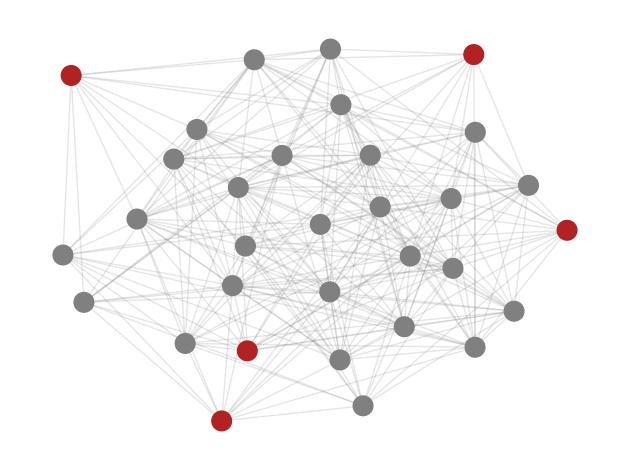

In [3]:
gcol.draw_mis_from_nodes(
    graph.nodes,
    active_color='firebrick',
    seed=12,
    use_labels=False,
    plot_margins=False,
)

Weights can be set with `graph.set_weights` (a list with the weight of
each node, by index).

If the argument `save_history` is set to `True`, you can also create
animations of the solution process.

```python
gcol.draw_mis_gif(
    "mis-gif.gif",
    graph.nodes,
    heur.history,
    seed=12, use_labels=False, plot_margins=False,
    duration=600
)
```